# 14｜31101 站的平日與週末借還型態

沿用 12 冊的案例站。借出依起站 ID 與借出時間，歸還依迄站 ID 與歸還時間。兩端各自限定在檔案時間的 2025 年 1 月，保留所有車種，時區尚未確認。沿用既有分析口徑，1/1、1/9、1/20 單列為特殊日。

每小時每日平均以該日型的全部日曆天數為分母，包含當小時無觀測事件的日期。無紀錄的時段以零件觀測事件計入，站點實際營運時段仍待核對。借還差額以借出減歸還計算，描述已觀測旅次。

In [1]:
import sqlite3
from pathlib import Path
from zipfile import ZipFile

import pandas as pd
from IPython.display import SVG, display

station_id = '31101'
with ZipFile('../data/raw/202501-capitalbikeshare-tripdata.zip') as archive:
    with archive.open('202501-capitalbikeshare-tripdata.csv') as csv:
        rides = pd.read_csv(csv, dtype='string', usecols=[
            'started_at', 'ended_at', 'start_station_id', 'end_station_id',
            'start_station_name', 'end_station_name'])

calendar = pd.DataFrame({'date': pd.date_range('2025-01-01', '2025-01-31')})
calendar['day_type'] = '一般平日'
calendar.loc[calendar.date.dt.dayofweek.ge(5), 'day_type'] = '週末'
calendar.loc[calendar.date.dt.day.isin([1, 9, 20]), 'day_type'] = '特殊日'
days = calendar.groupby('day_type').size().rename('天數')

events = []
expected = {}
for direction, endpoint, time_field in (
    ('借出', 'start', 'started_at'), ('歸還', 'end', 'ended_at')
):
    at_station = rides[f'{endpoint}_station_id'].str.strip().eq(station_id)
    records = rides.loc[at_station]
    times = pd.to_datetime(records[time_field], format='mixed', errors='raise')
    january = times.loc[times.ge('2025-01-01') & times.lt('2025-02-01')]
    expected[direction] = len(january)
    print(direction, '站名', records.loc[january.index, f'{endpoint}_station_name'].value_counts().to_dict())
    events.append(pd.DataFrame({'date': january.dt.normalize(), 'hour': january.dt.hour,
                                'direction': direction}))

events = pd.concat(events, ignore_index=True).merge(calendar, on='date', how='left', validate='many_to_one')
assert events.day_type.notna().all()

with sqlite3.connect(':memory:') as db:
    events.to_sql('events', db, index=False)
    hourly = pd.read_sql_query('''
        SELECT day_type, hour, direction, COUNT(*) AS trips
        FROM events
        GROUP BY day_type, hour, direction
    ''', db)

grid = pd.MultiIndex.from_product([days.index, range(24)], names=['day_type', 'hour'])
counts = (hourly.pivot(index=['day_type', 'hour'], columns='direction', values='trips')
          .reindex(grid).reindex(columns=['借出', '歸還']).fillna(0).astype(int))
totals = counts.groupby(level='day_type').sum()
direct = pd.crosstab(events.day_type, events.direction).reindex_like(totals).fillna(0)
assert totals.eq(direct).all().all()
assert totals.sum().to_dict() == expected

summary = totals.join(days)
summary['每日借出'] = summary['借出'] / days
summary['每日歸還'] = summary['歸還'] / days
display(summary.round(2))

daily = counts.div(days, level='day_type', axis=0)
daily['借還差額'] = daily['借出'] - daily['歸還']
display(counts.join(daily.add_prefix('每日')).round(2))

借出 站名 {'14th & V St NW': 1907}
歸還 站名 {'14th & V St NW': 1896}


,借出,歸還,天數,每日借出,每日歸還
day_type,,,,,
一般平日,1234,1193,20,61.70,59.65
特殊日,116,118,3,38.67,39.33
週末,557,585,8,69.62,73.12


direction      借出  歸還  每日借出  每日歸還  每日借還差額
day_type hour                            
一般平日     0     19   8  0.95  0.40    0.55
         1      4   2  0.20  0.10    0.10
         2      1   1  0.05  0.05    0.00
         3      3   8  0.15  0.40   -0.25
         4      2   5  0.10  0.25   -0.15
...            ..  ..   ...   ...     ...
週末       19    25  31  3.12  3.88   -0.75
         20    17  26  2.12  3.25   -1.12
         21    10  15  1.25  1.88   -0.62
         22    14  12  1.75  1.50    0.25
         23    18  16  2.25  2.00    0.25

[72 rows x 5 columns]

一般平日 08:00–08:59｜每日借出 7.15，歸還 2.10，借還差額 +5.05 件
週末 16:00–16:59｜每日借出 4.75，歸還 6.25，借還差額 -1.50 件


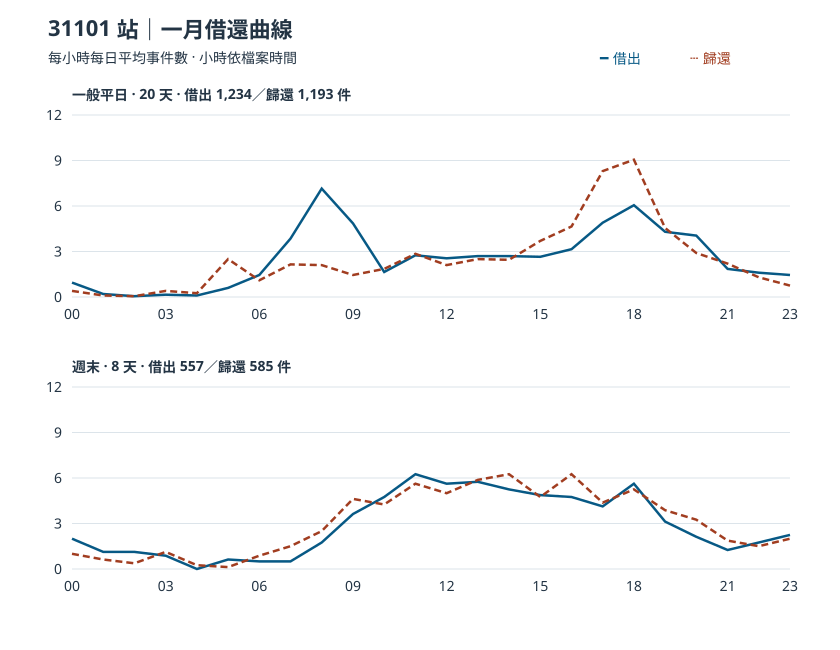

In [2]:
from html import escape
from math import ceil

# 兩張曲線共用同一縱軸。每個點代表該小時的每日平均事件量。
day_types = ['一般平日', '週末']
series = ['借出', '歸還']
max_value = daily.loc[day_types, series].max().max()
step = max(1, ceil(max_value / 4))
y_max = 4 * step

svg = ['<svg xmlns="http://www.w3.org/2000/svg" width="840" height="650" '
       'viewBox="0 0 840 650" role="img" aria-labelledby="title">',
       '<title id="title">31101 站一月平日與週末借還曲線</title>',
       '<rect width="840" height="650" fill="white"/>',
       '<g font-family="sans-serif" fill="#233444" font-size="14">',
       '<text x="48" y="36" font-size="22" font-weight="bold">31101 站｜一月借還曲線</text>',
       '<text x="48" y="63">每小時每日平均事件數 · 小時依檔案時間</text>',
       '<text x="600" y="63" fill="#075985">━ 借出</text>',
       '<text x="690" y="63" fill="#a13d20">┄ 歸還</text>']

left, right, height = 72, 790, 182
for day_type, top in zip(day_types, (115, 387)):
    frame = daily.loc[day_type]
    total = totals.loc[day_type]
    label = f'{day_type} · {days[day_type]} 天 · 借出 {total["借出"]:,}／歸還 {total["歸還"]:,} 件'
    svg.append(f'<text x="{left}" y="{top-15}" font-weight="bold">{escape(label)}</text>')
    bottom = top + height
    for tick in range(0, y_max + 1, step):
        y = bottom - tick * height / y_max
        svg.append(f'<path d="M{left} {y}H{right}" stroke="#dce4ea"/>')
        svg.append(f'<text x="{left-10}" y="{y+5}" text-anchor="end">{tick}</text>')
    for hour in [0, 3, 6, 9, 12, 15, 18, 21, 23]:
        x = left + hour * (right - left) / 23
        svg.append(f'<text x="{x:.1f}" y="{bottom+22}" text-anchor="middle">{hour:02d}</text>')
    for direction, color, dash in zip(series, ['#075985', '#a13d20'], ['none', '7 4']):
        points = [(left + hour * (right - left) / 23, bottom - value * height / y_max)
                  for hour, value in frame[direction].items()]
        coords = ' '.join(f'{x:.1f},{y:.1f}' for x, y in points)
        svg.append(f'<polyline points="{coords}" fill="none" stroke="{color}" '
                   f'stroke-width="2.5" stroke-dasharray="{dash}"/>')
svg.append('</g></svg>')
figure = Path('../figures/station_31101_january_profile.svg')
figure.write_text('\n'.join(svg), encoding='utf-8')
display(SVG(filename=str(figure)))

for day_type in day_types:
    frame = daily.loc[day_type]
    hour = frame['借還差額'].abs().idxmax()
    print(f'{day_type} {hour:02d}:00–{hour:02d}:59｜'
          f'每日借出 {frame.at[hour, "借出"]:.2f}，歸還 {frame.at[hour, "歸還"]:.2f}，'
          f'借還差額 {frame.at[hour, "借還差額"]:+.2f} 件')

一般平日借還差額的絕對值在 08:00–08:59 最大（每日多借出 5.05 件），週末則在 16:00–16:59 最大（每日多歸還 1.50 件）。這是 31101 站一月已記錄的借還型態，實際庫存仍需站點庫存和調度資料核對。